# Nuage de point 2D d'une image couleur ?

In [1]:
import numpy as np
import skimage.io as io
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

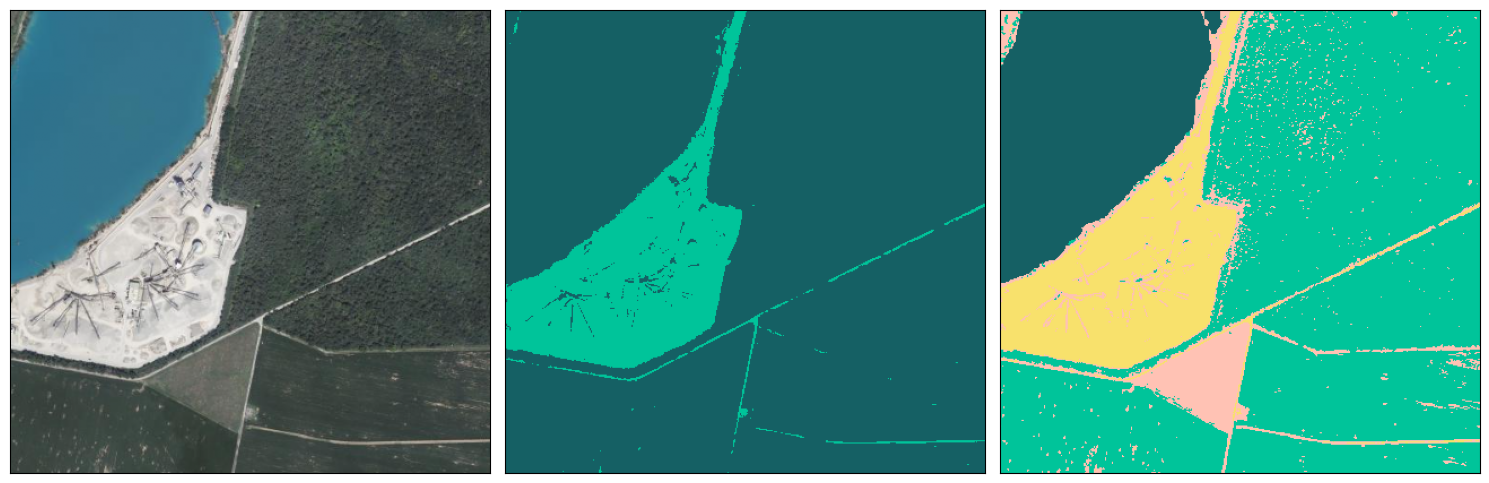

In [2]:
# Image
img = io.imread('dessenheim.png') / 255
w, h, d = img.shape

# Transform to a 2D numpy array
img_array = np.reshape(img, (w * h, d))

# Segmentation number
Ns = [2, 4]

# Colors for segmentation
codebook = np.array([
    (21, 96, 100),
    (0, 196, 154),
    (248, 225, 108),
    (255, 194, 180)
    ]) / 255

# Display
fig, axs = plt.subplots(1, len(Ns)+1, figsize=(15,10))
axs[0].imshow(img)
axs[0].set_xticks([])
axs[0].set_yticks([])

# Segmentation
for i, N in enumerate(Ns):

    # Fitting model
    kmeans = KMeans(n_clusters=N, random_state=0).fit(img_array)

    # Labels
    labels = kmeans.predict(img_array)

    # Segmentation
    g = codebook[labels].reshape(w, h, -1)
    g = np.array(g*255, dtype=np.uint8)

    # Display
    axs[i+1].imshow(g)
    axs[i+1].set_xticks([])
    axs[i+1].set_yticks([])

plt.tight_layout()
plt.savefig("kmeans-appli.svg", bbox_inches="tight")
plt.show()